# Data Cleaning

In this notebook we clean the emotion dataset (tweets labelled as anger, fear, joy, love, sadness or surprise).

Steps: load the data, check missing values, check labels, remove duplicates, check formatting, check outliers and save the clean files.

In [1]:
import re, json, unicodedata, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold"})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, IMG, REP = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "images", ROOT / "reports"
for p in (PROC, IMG, REP):
    p.mkdir(parents=True, exist_ok=True)

EMOTIONS = ["anger", "fear", "joy", "love", "sadness", "surprise"]
SPLITS = ["train", "val", "test"]
RANDOM_STATE = 42

NOTES = {}

def save_fig(fig, name):
    fig.savefig(IMG / f"{name}.png", dpi=200, bbox_inches="tight")

def note(name, text):
    NOTES[name] = text
    print("TAKEAWAY ->", text)

## 1. Load the data

The files have no header row, so we read them with `header=None` (with the default setting pandas uses the first row as column names and one sample is lost). If a file does have a header row, it is removed.

In [2]:
import csv

def load_split(name):
    for ext in ("csv", "txt"):
        f = RAW / f"{name}.{ext}"
        if f.exists():
            df = pd.read_csv(f, sep=";", header=None, names=["text", "label"],
                             quoting=csv.QUOTE_NONE, on_bad_lines="warn", encoding="utf-8")
            if str(df.iloc[0]["label"]).strip().lower() in ("label", "text"):
                df = df.iloc[1:].reset_index(drop=True)
            return df
    raise FileNotFoundError(f"Could not find {name}.csv or {name}.txt in {RAW}.")

raw = {s: load_split(s) for s in SPLITS}
overview = pd.DataFrame({s: {"rows": len(d), "columns": d.shape[1]} for s, d in raw.items()}).T
overview.loc["total"] = overview.sum()
overview

,rows,columns
train,16000,2
val,2000,2
test,2000,2
total,20000,6


In [3]:
print("Column dtypes:\n", raw["train"].dtypes, "\n")
raw["train"].head(8)

Column dtypes:
 text     object
label    object
dtype: object 



,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
5,ive been feeling a little burdened lately wasn...,sadness
6,ive been taking or milligrams or times recomme...,surprise
7,i feel as confused about life as a teenager or...,fear


## 2. Missing values

Checking for empty values and blank texts.

In [4]:
rows = []
for s, d in raw.items():
    rows.append({
        "split": s, "rows": len(d),
        "missing_text": int(d.text.isna().sum()),
        "missing_label": int(d.label.isna().sum()),
        "empty_or_blank_text": int((d.text.fillna("").astype(str).str.strip() == "").sum()),
    })
missing_report = pd.DataFrame(rows).set_index("split")
missing_report

,rows,missing_text,missing_label,empty_or_blank_text
split,,,,
train,16000,0,0,0
val,2000,0,0,0
test,2000,0,0,0


Rows with a missing text or label are dropped because they cannot be used for training.

## 3. Labels

Checking the label spellings. Different spellings of the same label would create extra classes.

In [5]:
raw_labels = pd.DataFrame({s: d.label.value_counts(dropna=False) for s, d in raw.items()}).fillna(0).astype(int)
raw_labels.index = raw_labels.index.map(repr)
print("Distinct raw label spellings:", len(raw_labels))
unexpected = [l for l in raw_labels.index if l.strip("'").strip().lower() not in EMOTIONS]
print("Spellings that are NOT one of the 6 emotions:", unexpected if unexpected else "none")
raw_labels

Distinct raw label spellings: 6
Spellings that are NOT one of the 6 emotions: none


,train,val,test
label,,,
'joy',5362,704,695
'sadness',4666,550,581
'anger',2159,275,275
'fear',1937,212,224
'love',1304,178,159
'surprise',572,81,66


Labels are converted to lower case and stripped. Rows with a label that is not one of the 6 emotions are dropped (this also removes a header row if there is one).

## 4. Duplicates

Three things are checked:
- exact duplicates (same text, same label)
- same text with different labels
- same text in different splits (train/val/test), which is data leakage

In [6]:
def key(s):
    return s.fillna("").astype(str).str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

rows = []
for s, d in raw.items():
    k = key(d.text); lab = d.label.astype(str).str.strip().str.lower()
    tmp = pd.DataFrame({"k": k, "lab": lab})
    exact = tmp.duplicated(["k", "lab"]).sum()
    nunq = tmp.groupby("k")["lab"].nunique()
    rows.append({"split": s, "exact_duplicate_rows": int(exact),
                 "texts_with_conflicting_labels": int((nunq > 1).sum())})
dup_report = pd.DataFrame(rows).set_index("split")
display(dup_report)

keys = {s: set(key(d.text)) for s, d in raw.items()}
leak = pd.DataFrame({
    "pair": ["train ∩ val", "train ∩ test", "val ∩ test"],
    "shared_texts": [len(keys["train"] & keys["val"]), len(keys["train"] & keys["test"]), len(keys["val"] & keys["test"])],
})
leak

,exact_duplicate_rows,texts_with_conflicting_labels
split,,
train,1,30
val,0,2
test,0,0


,pair,shared_texts
0,train ∩ val,5
1,train ∩ test,11
2,val ∩ test,3


In [7]:
d = raw["train"].copy(); d["k"] = key(d.text); d["label"] = d.label.astype(str).str.strip().str.lower()
conf = d.groupby("k")["label"].agg(lambda x: sorted(set(x)))
conf = conf[conf.map(len) > 1]
print(f"{len(conf)} texts in train carry more than one label. Examples:")
conf.head(8).to_frame("labels")

30 texts in train carry more than one label. Examples:


,labels
k,
i am not amazing or great at photography but i feel passionate about it,"[joy, love]"
i began to feel accepted by gaia on her own terms,"[joy, love]"
i bet taylor swift basks in the knowledge that the boys she writes songs about probably feel tortured,"[anger, fear]"
i cant escape the tears of sadness and just true grief i feel at the loss of my sweet friend and sister,"[joy, love]"
i could feel myself hit this strange foggy wall,"[fear, surprise]"
i feel a remembrance of the strange by justin aryiku falls into the latter category,"[fear, surprise]"
i feel im being generous with that statement,"[joy, love]"
i feel kind of strange,"[fear, surprise]"


Exact duplicates: keep only the first one. Same text with different labels: remove all copies. Texts that appear in test are removed from train and val so the test set stays untouched.

## 5. Formatting

Counting the rows with uppercase letters, extra spaces, URLs, HTML tags, digits, punctuation and non-ASCII characters.

In [8]:
def format_issues(d):
    t = d.text.fillna("").astype(str)
    return {
        "leading/trailing spaces": int((t != t.str.strip()).sum()),
        "multiple spaces": int(t.str.contains(r"\s{2,}").sum()),
        "has UPPERCASE": int(t.str.contains(r"[A-Z]").sum()),
        "non-ASCII chars": int(t.map(lambda x: not x.isascii()).sum()),
        "has digits": int(t.str.contains(r"\d").sum()),
        "has URL": int(t.str.contains(r"https?://|www\.").sum()),
        "has HTML tags": int(t.str.contains(r"<[^>]+>").sum()),
        "has punctuation": int(t.str.contains(r"[^\w\s]").sum()),
    }
fmt = pd.DataFrame({s: format_issues(d) for s, d in raw.items()})
fmt

,train,val,test
leading/trailing spaces,0,0,0
multiple spaces,0,0,0
has UPPERCASE,0,0,0
non-ASCII chars,0,0,0
has digits,0,0,0
has URL,0,0,0
has HTML tags,0,0,0
has punctuation,0,0,0


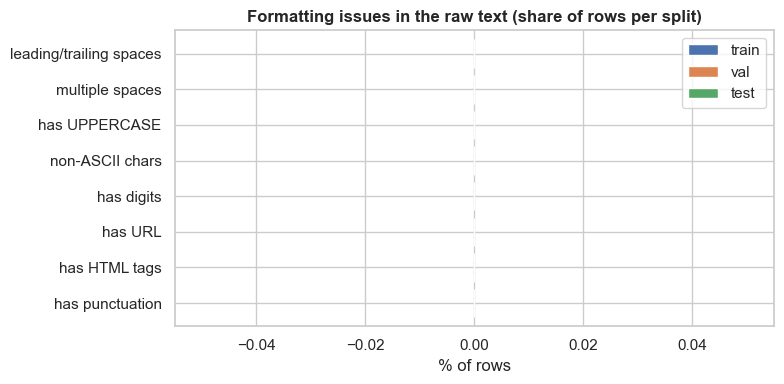

TAKEAWAY -> In train, 'leading/trailing spaces' is the most common formatting trait (0.0% of rows); 'has UPPERCASE' affects 0.0% and 'has URL' 0.0%.


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
fmt_pct = (fmt / pd.Series({s: len(d) for s, d in raw.items()}) * 100)
fmt_pct.plot.barh(ax=ax, width=0.8)
ax.set_xlabel("% of rows"); ax.set_title("Formatting issues in the raw text (share of rows per split)")
ax.invert_yaxis(); plt.tight_layout(); save_fig(fig, "01_format_issues"); plt.show()
worst = fmt_pct["train"].sort_values(ascending=False)
note("01_format_issues", f"In train, '{worst.index[0]}' is the most common formatting trait ({worst.iloc[0]:.1f}% of rows); "
     f"'has UPPERCASE' affects {fmt_pct.loc['has UPPERCASE','train']:.1f}% and 'has URL' {fmt_pct.loc['has URL','train']:.1f}%.")

The chart shows how many rows have each formatting problem. The cleaning function is applied anyway to make sure the text is consistent.

## 6. Outliers

The only numeric thing in this dataset is the text length, so outliers are very short or very long texts. I use the IQR rule on the train set: lower = Q1 - 1.5 x IQR and upper = Q3 + 1.5 x IQR.

Train word count: Q1=11, Q3=25, IQR=14  ->  fences: [1.0, 46.0] words


,train,val,test
min,2.00,2.00,3.00
median,17.00,17.00,17.00
mean,19.17,18.87,19.15
max,66.00,61.00,61.00
# below lower fence,0.00,0.00,0.00
# above upper fence,375.00,43.00,49.00
% outliers,2.34,2.15,2.45


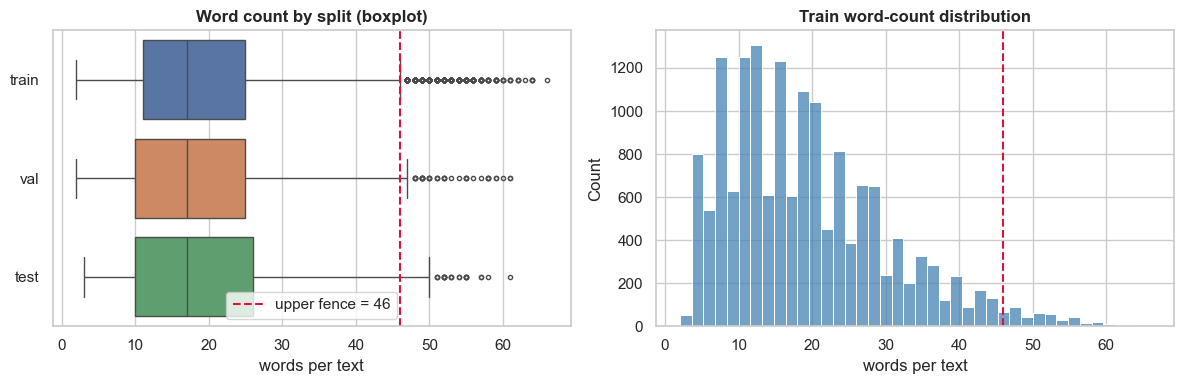

TAKEAWAY -> Texts are short (median 17 words); the IQR upper fence is 46 words and 2.34% of train rows lie above it (longest = 66 words).


In [10]:
wc = {s: d.text.fillna("").astype(str).str.split().str.len() for s, d in raw.items()}
q1, q3 = wc["train"].quantile([0.25, 0.75]); iqr = q3 - q1
lower, upper = max(q1 - 1.5 * iqr, 1), q3 + 1.5 * iqr
print(f"Train word count: Q1={q1:.0f}, Q3={q3:.0f}, IQR={iqr:.0f}  ->  fences: [{lower:.1f}, {upper:.1f}] words")

out_tbl = pd.DataFrame({s: {"min": w.min(), "median": w.median(), "mean": round(w.mean(), 2), "max": w.max(),
                            "# below lower fence": int((w < lower).sum()), "# above upper fence": int((w > upper).sum()),
                            "% outliers": round(((w < lower) | (w > upper)).mean() * 100, 2)} for s, w in wc.items()})
display(out_tbl)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=pd.DataFrame(wc), orient="h", ax=axes[0], showfliers=True, flierprops={"markersize": 3})
axes[0].axvline(upper, color="crimson", ls="--", label=f"upper fence = {upper:.0f}")
axes[0].set_xlabel("words per text"); axes[0].set_title("Word count by split (boxplot)"); axes[0].legend()
sns.histplot(wc["train"], bins=40, ax=axes[1], color="steelblue")
axes[1].axvline(upper, color="crimson", ls="--"); axes[1].set_xlabel("words per text"); axes[1].set_title("Train word-count distribution")
plt.tight_layout(); save_fig(fig, "02_length_outliers"); plt.show()
note("02_length_outliers", f"Texts are short (median {wc['train'].median():.0f} words); the IQR upper fence is {upper:.0f} words and "
     f"{(wc['train'] > upper).mean()*100:.2f}% of train rows lie above it (longest = {wc['train'].max()} words).")

In [11]:
d = raw["train"].assign(words=wc["train"])
print("Shortest texts:");  display(d.nsmallest(5, "words")[["text", "label", "words"]])
print("Longest texts:");   display(d.nlargest(5, "words")[["text", "label", "words"]])

Shortest texts:


,text,label,words
4150,earth crake,fear,2
4997,during lectures,joy,2
8824,in sweden,fear,2
9355,no response,anger,2
12204,one night,joy,2


Longest texts:


,text,label,words
6322,i guess which meant or so i assume no photos n...,sadness,66
46,i lost my special mind but don t worry i m sti...,joy,64
7222,i am happier this year in all ways i am just g...,joy,64
9618,i feel you i dont believ in you but i keep my ...,joy,64
9626,i feel in my bones like nobody cares if im her...,sadness,64


Most texts are short and a few are long. The longest texts are normal sentences, so I keep them and only mark them with an `is_length_outlier` column.

## 7. Clean the data

All the steps are applied below and the number of rows removed at each step is counted.

In [12]:
URL_RE  = re.compile(r"(https?://\S+|www\.\S+)")
HTML_RE = re.compile(r"<[^>]+>")

def normalize_text(t):
    t = unicodedata.normalize("NFKC", str(t))
    t = HTML_RE.sub(" ", t)
    t = URL_RE.sub(" ", t)
    t = t.lower()
    return re.sub(r"\s+", " ", t).strip()

log, clean = {}, {}
for s, df in raw.items():
    d = df.copy(); e = {"raw_rows": len(d)}
    d["text"] = d["text"].astype("string"); d["label"] = d["label"].astype("string").str.strip().str.lower()

    m = d.text.isna() | d.label.isna();                        e["dropped_missing_values"] = int(m.sum()); d = d[~m]
    d["text"] = d.text.map(normalize_text)
    m = d.text.eq("");                                         e["dropped_empty_text"] = int(m.sum()); d = d[~m]
    m = ~d.label.isin(EMOTIONS);                               e["dropped_invalid_label"] = int(m.sum()); d = d[~m]
    m = d.duplicated(["text", "label"]);                       e["dropped_exact_duplicates"] = int(m.sum()); d = d[~m]
    m = d.groupby("text")["label"].transform("nunique") > 1;   e["dropped_conflicting_labels"] = int(m.sum()); d = d[~m]
    clean[s], log[s] = d.reset_index(drop=True), e

for s, ref in [("val", {"test"}), ("train", {"test", "val"})]:
    ref_texts = set().union(*[set(clean[r].text) for r in ref])
    m = clean[s].text.isin(ref_texts)
    log[s]["dropped_leakage_vs_" + "+".join(sorted(ref))] = int(m.sum())
    clean[s] = clean[s][~m].reset_index(drop=True)

w = clean["train"].text.str.split().str.len()
q1, q3 = w.quantile([0.25, 0.75]); upper = q3 + 1.5 * (q3 - q1)
for s, d in clean.items():
    d["is_length_outlier"] = d.text.str.split().str.len() > upper
    log[s]["flagged_length_outliers_kept"] = int(d.is_length_outlier.sum())
    log[s]["clean_rows"] = len(d)

cleaning_log = pd.DataFrame(log).fillna(0).astype(int)
cleaning_log = cleaning_log.loc[[i for i in cleaning_log.index if i not in ("flagged_length_outliers_kept", "clean_rows")] + ["flagged_length_outliers_kept", "clean_rows"]]
cleaning_log

,train,val,test
raw_rows,16000,2000,2000
dropped_missing_values,0,0,0
dropped_empty_text,0,0,0
dropped_invalid_label,0,0,0
dropped_exact_duplicates,1,0,0
dropped_conflicting_labels,60,4,0
dropped_leakage_vs_test+val,16,0,0
dropped_leakage_vs_test,0,3,0
flagged_length_outliers_kept,375,43,49
clean_rows,15923,1993,2000


## 8. Check the result

Asserts to make sure no problem is left, and a plot to check that the class proportions did not change.

All cleaning checks passed ✔


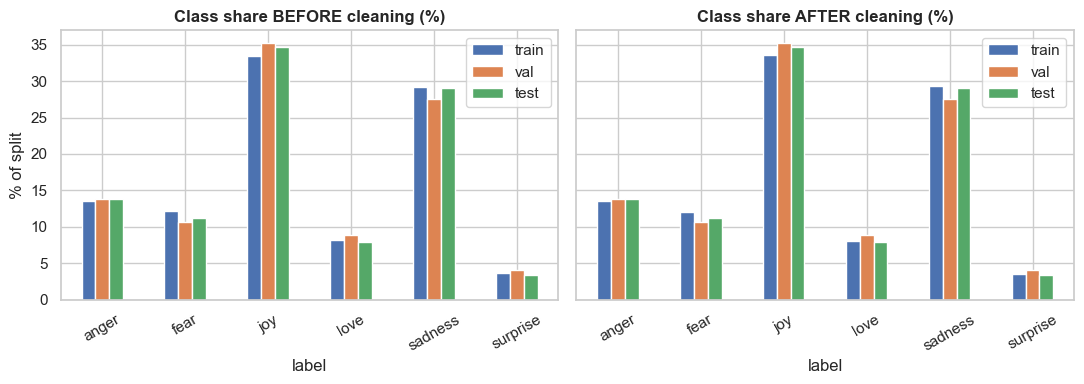

TAKEAWAY -> Cleaning changed no class's share by more than 0.11 percentage points, so it did not distort the label distribution.


In [13]:
for s, d in clean.items():
    assert d.text.notna().all() and d.label.notna().all(),          f"{s}: missing values remain"
    assert (d.text.str.len() > 0).all(),                            f"{s}: empty texts remain"
    assert set(d.label) <= set(EMOTIONS),                           f"{s}: invalid labels remain"
    assert not d.duplicated(["text"]).any(),                        f"{s}: duplicate texts remain"
    assert not d.text.str.contains(r"\s{2,}|^\s|\s$").any(),        f"{s}: whitespace issues remain"
    assert not d.text.str.contains(r"[A-Z]").any(),                 f"{s}: uppercase remains"
assert not (set(clean["train"].text) & set(clean["test"].text)),    "train/test leakage remains"
assert not (set(clean["train"].text) & set(clean["val"].text)),     "train/val leakage remains"
assert not (set(clean["val"].text)   & set(clean["test"].text)),    "val/test leakage remains"
print("All cleaning checks passed ✔")

before = pd.DataFrame({s: raw[s].label.astype(str).str.strip().str.lower().value_counts(normalize=True) for s in SPLITS}).reindex(EMOTIONS)
after  = pd.DataFrame({s: clean[s].label.value_counts(normalize=True) for s in SPLITS}).reindex(EMOTIONS)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
(before * 100).plot.bar(ax=axes[0], rot=30); axes[0].set_title("Class share BEFORE cleaning (%)")
(after * 100).plot.bar(ax=axes[1], rot=30);  axes[1].set_title("Class share AFTER cleaning (%)")
for a in axes: a.set_ylabel("% of split")
plt.tight_layout(); save_fig(fig, "03_class_share_before_after"); plt.show()
shift = (after - before).abs().max().max() * 100
note("03_class_share_before_after", f"Cleaning changed no class's share by more than {shift:.2f} percentage points, so it did not distort the label distribution.")

The class proportions before and after cleaning are almost the same, so cleaning did not change the distribution of the data.

## 9. Save the clean data

In [14]:
for s, d in clean.items():
    d.to_csv(PROC / f"{s}_clean.csv", index=False)
cleaning_log.to_json(REP / "cleaning_log.json", indent=2)

with open(REP / "figure_notes_cleaning.md", "w") as f:
    f.write("# Figure notes — cleaning\n\n")
    for k, v in NOTES.items():
        f.write(f"- **images/{k}.png** — {v}\n")

print("Saved:", *[f"data/processed/{s}_clean.csv ({len(clean[s]):,} rows)" for s in SPLITS], "reports/cleaning_log.json", sep="\n  ")

Saved:
  data/processed/train_clean.csv (15,923 rows)
  data/processed/val_clean.csv (1,993 rows)
  data/processed/test_clean.csv (2,000 rows)
  reports/cleaning_log.json
